#1. Data Understanding and Preparation

Importing required libraries


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Make plots look consistent and readable
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)


Loading and Inspecting DataSet

In [ ]:
import os
import pandas as pd

# Mount Google Drive if we're in Colab
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    pass  # not in Colab

# Try local first, then Drive
if os.path.exists('ai_job_dataset.csv'):
    csv_path = 'ai_job_dataset.csv'
else:
    csv_path = '/content/drive/MyDrive/ai_job_dataset.csv'

print(f"Loading from: {csv_path}\n")
df = pd.read_csv(csv_path)

#shape of the dataset
print("dataset shape", df.shape)
print("")

#data info
df.info()
display(df.describe())
display(df.head())






Mounted at /content/drive
Loading from: /content/drive/MyDrive/ai_job_dataset.csv

dataset shape (15000, 19)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 19 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   job_id                  15000 non-null  object 
 1   job_title               15000 non-null  object 
 2   salary_usd              15000 non-null  int64  
 3   salary_currency         15000 non-null  object 
 4   experience_level        15000 non-null  object 
 5   employment_type         15000 non-null  object 
 6   company_location        15000 non-null  object 
 7   company_size            15000 non-null  object 
 8   employee_residence      15000 non-null  object 
 9   remote_ratio            15000 non-null  int64  
 10  required_skills         15000 non-null  object 
 11  education_required      15000 non-null  object 
 12  years_experience        15000 non-

,salary_usd,remote_ratio,years_experience,job_description_length,benefits_score
count,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000
mean,115348.965133,49.483333,6.253200,1503.314733,7.504273
std,60260.940438,40.812712,5.545768,576.127083,1.450870
min,32519.000000,0.000000,0.000000,500.000000,5.000000
25%,70179.750000,0.000000,2.000000,1003.750000,6.200000
50%,99705.000000,50.000000,5.000000,1512.000000,7.500000
75%,146408.500000,100.000000,10.000000,2000.000000,8.800000
max,399095.000000,100.000000,19.000000,2499.000000,10.000000


,job_id,job_title,salary_usd,salary_currency,experience_level,employment_type,company_location,company_size,employee_residence,remote_ratio,required_skills,education_required,years_experience,industry,posting_date,application_deadline,job_description_length,benefits_score,company_name
0,AI00001,AI Research Scientist,90376,USD,SE,CT,China,M,China,50,"Tableau, PyTorch, Kubernetes, Linux, NLP",Bachelor,9,Automotive,2024-10-18,2024-11-07,1076,5.9,Smart Analytics
1,AI00002,AI Software Engineer,61895,USD,EN,CT,Canada,M,Ireland,100,"Deep Learning, AWS, Mathematics, Python, Docker",Master,1,Media,2024-11-20,2025-01-11,1268,5.2,TechCorp Inc
2,AI00003,AI Specialist,152626,USD,MI,FL,Switzerland,L,South Korea,0,"Kubernetes, Deep Learning, Java, Hadoop, NLP",Associate,2,Education,2025-03-18,2025-04-07,1974,9.4,Autonomous Tech
3,AI00004,NLP Engineer,80215,USD,SE,FL,India,M,India,50,"Scala, SQL, Linux, Python",PhD,7,Consulting,2024-12-23,2025-02-24,1345,8.6,Future Systems
4,AI00005,AI Consultant,54624,EUR,EN,PT,France,S,Singapore,100,"MLOps, Java, Tableau, Python",Master,0,Media,2025-04-15,2025-06-23,1989,6.6,Advanced Robotics


Missing/null values

In [ ]:
df.isnull().sum()


,0
job_id,0
job_title,0
salary_usd,0
salary_currency,0
experience_level,0
employment_type,0
company_location,0
company_size,0
employee_residence,0
remote_ratio,0


Duplicate data

In [ ]:
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate job IDs:", df['job_id'].duplicated().sum())

Duplicate rows: 0
Duplicate job IDs: 0


Data by category

In [ ]:
categorical_columns = [
    'salary_currency',
    'experience_level',
    'employment_type',
    'company_location',
    'company_size',
    'employee_residence',
    'education_required',
    'industry'
]

for col in categorical_columns:
    print(f"\n{df[col].value_counts()}:")


salary_currency
USD    11957
EUR     2314
GBP      729
Name: count, dtype: int64:

experience_level
MI    3781
EX    3760
SE    3741
EN    3718
Name: count, dtype: int64:

employment_type
FT    3812
FL    3758
CT    3721
PT    3709
Name: count, dtype: int64:

company_location
Germany           814
Denmark           778
Canada            769
France            769
Austria           765
Singapore         764
China             763
India             754
Sweden            752
Israel            751
Ireland           750
Switzerland       746
Japan             733
Finland           733
Australia         732
Netherlands       731
United Kingdom    729
United States     724
South Korea       722
Norway            721
Name: count, dtype: int64:

company_size
S    5007
L    4998
M    4995
Name: count, dtype: int64:

employee_residence
Sweden            790
France            781
Denmark           777
Austria           776
India             772
Germany           769
South Korea       763
Canada    

Inconsistant values check (checks to make sure that there arent abnormal values such as negative years of experience or 100 years of experience)

In [ ]:
numerical_columns = [
    'salary_usd',
    'remote_ratio',
    'years_experience',
    'job_description_length',
    'benefits_score'

]

for col in numerical_columns:
    print(f"\n{col}:")
    print('minimum:', df[col].min())
    print('maximum:', df[col].max())



salary_usd:
minimum: 32519
maximum: 399095

remote_ratio:
minimum: 0
maximum: 100

years_experience:
minimum: 0
maximum: 19

job_description_length:
minimum: 500
maximum: 2499

benefits_score:
minimum: 5.0
maximum: 10.0


The data showed posting_date and application_deadline as a string which isnt ideal. Converting the str to datetime64 datatype.

In [ ]:

df['posting_date'] = pd.to_datetime(df['posting_date'])
df['application_deadline'] = pd.to_datetime(df['application_deadline'])

print(df['posting_date'].head())
print(df['application_deadline'].head())


0   2024-10-18
1   2024-11-20
2   2025-03-18
3   2024-12-23
4   2025-04-15
Name: posting_date, dtype: datetime64[ns]
0   2024-11-07
1   2025-01-11
2   2025-04-07
3   2025-02-24
4   2025-06-23
Name: application_deadline, dtype: datetime64[ns]


#2. Detailed Exploratory Data Analysis (EDA)

### Salary by Experience Level
This chart examines the relationship between experience level (EN, MI, SE, EX) and salary.

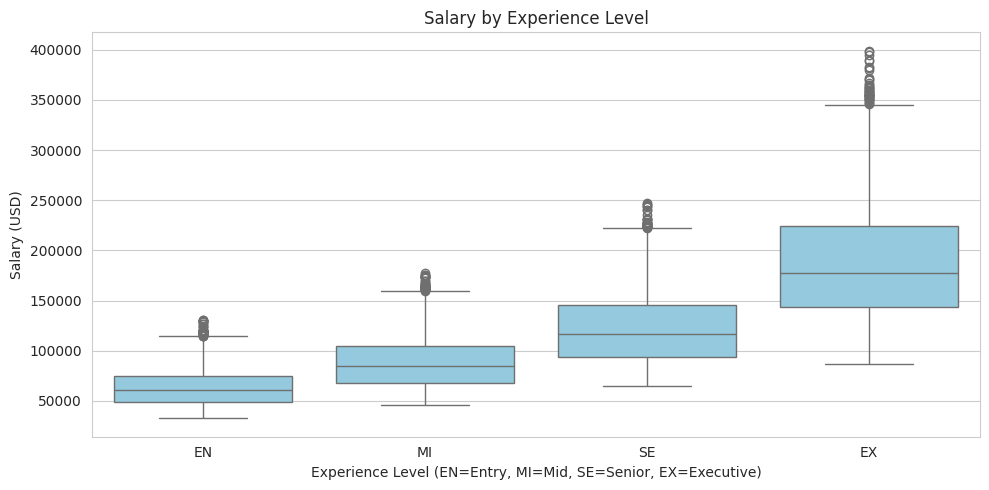

In [ ]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=df, x='experience_level', y='salary_usd',
            order=['EN', 'MI', 'SE', 'EX'], color='skyblue')
plt.title('Salary by Experience Level')
plt.xlabel('Experience Level (EN=Entry, MI=Mid, SE=Senior, EX=Executive)')
plt.ylabel('Salary (USD)')
plt.tight_layout()
plt.show()

Experience level is the strongest driver of salary in the dataset. There is a clear, consistent staircase effect: Entry-level roles average around $50k - $75k, while Executive roles average over $140k. The median salary increases significantly with each step up in experience.

### Salary by Country
This chart displays the median salary for the top 10 highest-paying countries.

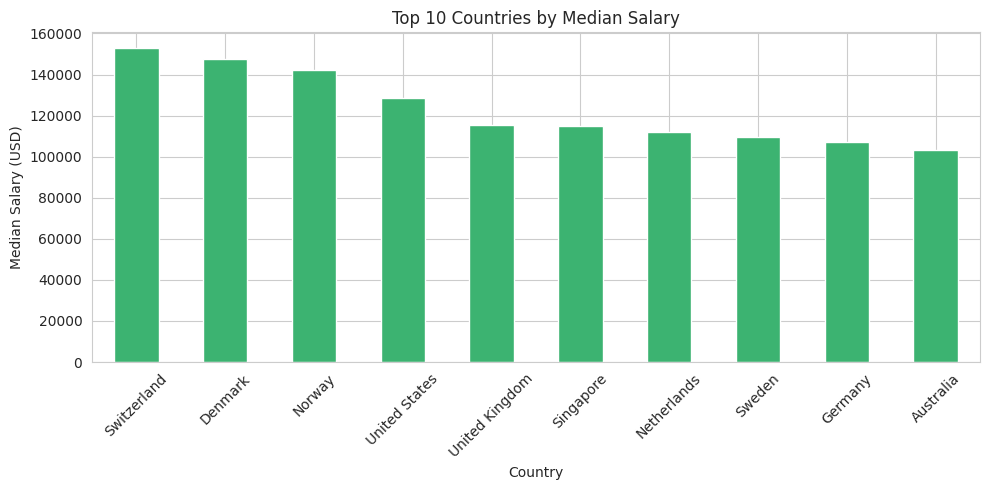

In [ ]:
# Get top 10 countries by median salary
top_countries = df.groupby('company_location')['salary_usd'].median().sort_values(ascending=False).head(10)

plt.figure(figsize=(10, 5))
top_countries.plot(kind='bar', color='mediumseagreen')
plt.title('Top 10 Countries by Median Salary')
plt.ylabel('Median Salary (USD)')
plt.xlabel('Country')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Salary varies significantly by country. The top-paying countries like Switzerland, Denmark, and Norway offer median salaries well above the other countries. However, the salary gap between the #1 country and the #10 country is smaller than the gap between an Entry-level and Executive role, confirming that experience level matters more than location.

### Salary by Remote Work Ratio
This chart examines whether fully remote (100), hybrid (50), or on-site (0) roles command different salaries.

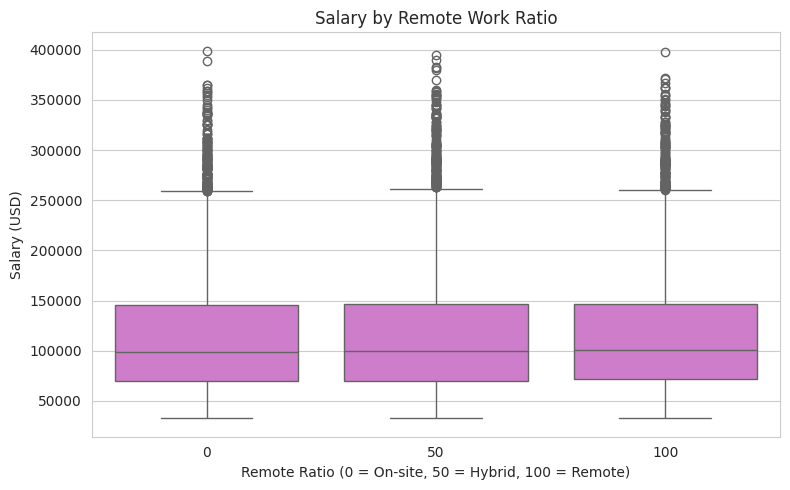

In [ ]:
# Ploting the fully remote (100), hybrid (50), or on-site (0) roles for average salaries
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x='remote_ratio', y='salary_usd', color='orchid')
plt.title('Salary by Remote Work Ratio')
plt.xlabel('Remote Ratio (0 = On-site, 50 = Hybrid, 100 = Remote)')
plt.ylabel('Salary (USD)')
plt.tight_layout()
plt.show()

The box plots for on-site, hybrid, and fully remote roles are nearly identical. The median salary for all three categories is roughly the same. Working remotely does not appear to offer a salary premium or penalty in this dataset.

### Salary by Minimum Education Required

This chart looks at whether or not the minimum education required of a job has a significant impact on salary.

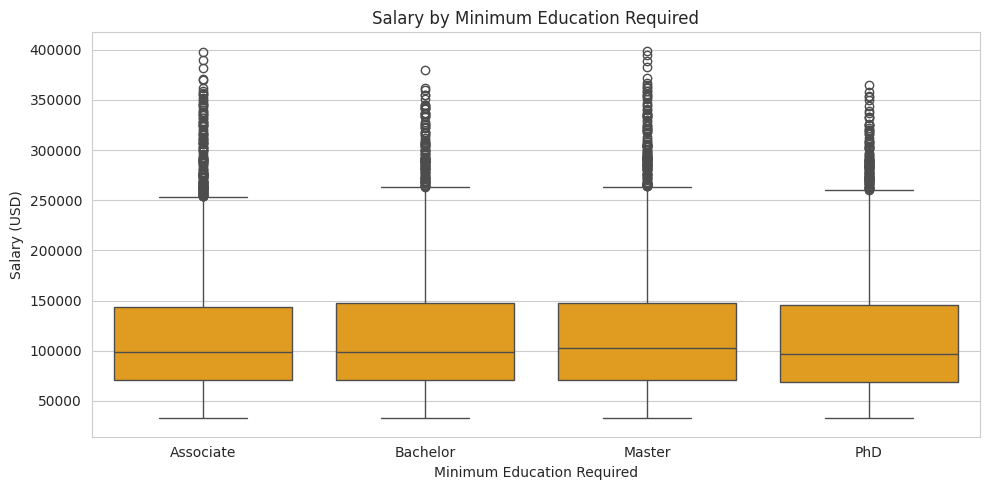

In [ ]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=df, x='education_required', y='salary_usd',
            order=["Associate", "Bachelor", "Master", "PhD"], color='orange')
plt.title('Salary by Minimum Education Required')
plt.xlabel('Minimum Education Required')
plt.ylabel('Salary (USD)')
plt.tight_layout()
plt.show()

The box plots between all four education requirnments remains nearly the exact same. There appears to be no trend at all between various educations, suggesting the idea that as long as a person has an associate's degree, their minimum education has little to no impact on their salary.

### Skills Analysis
This section addresses the third research question: which skills appear most in high-paying jobs and which are most in demand.

The `required_skills` column stores multiple skills as a comma-separated string (e.g., "Python, SQL, Docker"). To analyze this data, the column is split into a long-form DataFrame where each row represents a single job-skill pair. This transformation allows for calculating skill frequencies and average salaries.




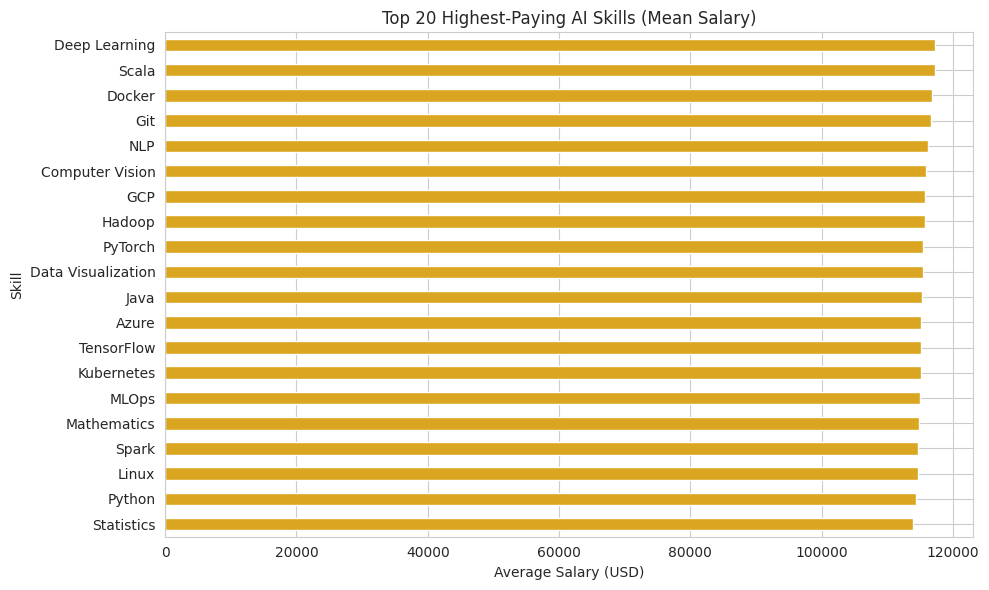

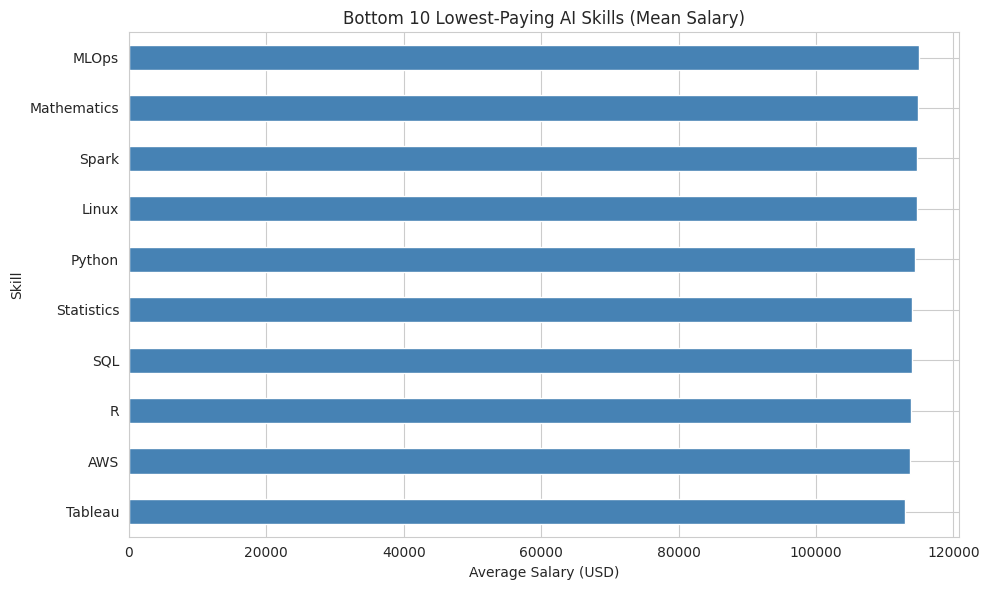

In [ ]:
# Split the comma-separated string into individual rows
skills_long = df[['job_id', 'salary_usd', 'experience_level']].copy()
skills_long['skills'] = df['required_skills'].str.split(', ')
skills_long = skills_long.explode('skills')
skills_long['skills'] = skills_long['skills'].str.strip()

# Calculate the average salary for each skill
skill_salary = skills_long.groupby('skills')['salary_usd'].mean().sort_values(ascending=False)

plt.figure(figsize=(10, 6))
# Plot the top 20 highest-paying skills
skill_salary.head(20).plot(kind='barh', color='goldenrod')
plt.title('Top 20 Highest-Paying AI Skills (Mean Salary)')
plt.xlabel('Average Salary (USD)')
plt.ylabel('Skill')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


# Calculate the average salary for each skill
skill_salary = (
    skills_long.groupby('skills')['salary_usd']
    .mean()
    .sort_values(ascending=False)
)

bottom_10 = skill_salary.tail(10).sort_values()

plt.figure(figsize=(10, 6))

bottom_10.plot(kind='barh', color='steelblue')

plt.title('Bottom 10 Lowest-Paying AI Skills (Mean Salary)')
plt.xlabel('Average Salary (USD)')
plt.ylabel('Skill')

plt.tight_layout()
plt.show()

The first chart shows that every skill pays almost exactly the same average salary (around $115,000). The bars are flat. While foundational skills like Python and SQL are the most in-demand, they do not offer a higher salary than other skills. Because every skill pays the same, acquiring a specific niche skill does not increase expected pay in this dataset. This flat trend supports earlier findings that the dataset is synthetic, meaning skills were likely assigned to jobs randomly without affecting salary.
The second chart helps reinforce the conclusion of the first. The bottom 10 skills share overlap with the top 20 skills, meaning there are less than 30 skills in total. We can also see that the salaries of the bottom skills deviate only slightly from the top skills, reinforcing the conclusion made earlier.

### Industry Analysis
Similar to the skills analysis, this chart below tracks average salary across different industries. The code here is simpler as only one industry is provided for each row.

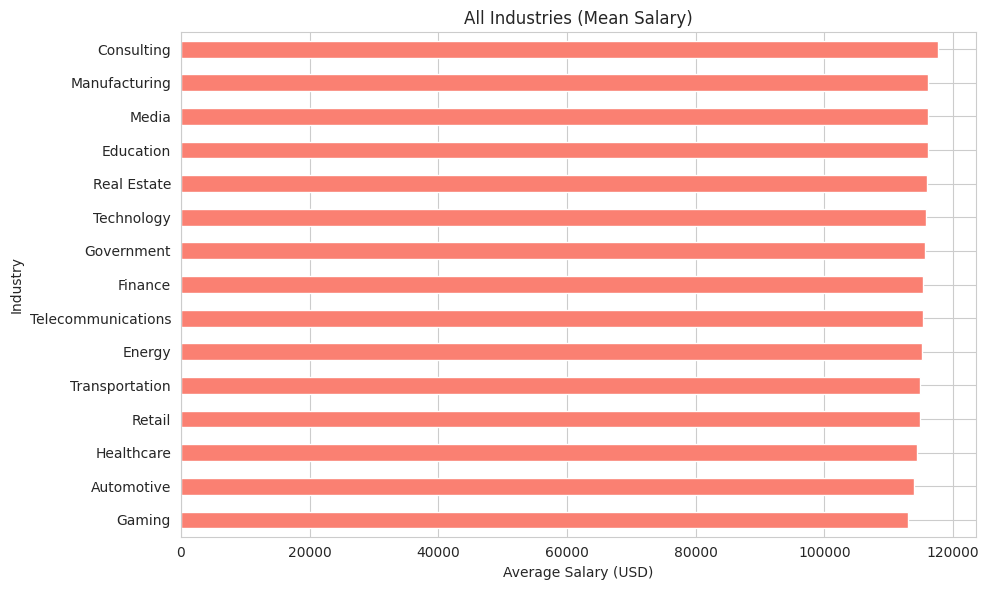

In [ ]:
# Keep only the columns needed
industry_data = df[['salary_usd', 'industry']].copy()

# Remove missing industries if necessary
industry_data = industry_data.dropna(subset=['industry'])

# Calculate the average salary for each industry
industry_salary = (
    industry_data.groupby('industry')['salary_usd']
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 6))

industry_salary.plot(
    kind='barh',
    color='salmon'
)

plt.title('All Industries (Mean Salary)')
plt.xlabel('Average Salary (USD)')
plt.ylabel('Industry')
plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

Similar to the skills chart, we see with this chart that the distribution is nearly uniform across all of the different industries. This implies that industry is not at all a large factor in deciding a person's salary.

#3. Methodology: